# Measuring cell - cell or neigh-neigh distances

In [1]:
import muspan as ms
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 
import os
import json

load in domains w neighbourhoods

In [2]:
directory = r"./250529_saved_domains_w_neighbourhoods_COMB"

saved_domains = os.listdir(directory)

domains = []

for s_domain in saved_domains:
    domain = ms.io.load_domain(os.path.join(directory,s_domain))
    domains.append(domain)

MuSpAn domain loaded successfully. Domain summary:
Domain name: updated_B24-577 AB001 COMB Rx2 R2_Scan1_Stitched.csv
Number of objects: 598984
Collections: ['Cell centres']
Labels: ['Phenotype', 'ROI', 'CD8 intensity', 'PDPN intensity', 'aSMA intensity', 'PDGFRa intensity', 'FAP intensity', 'panCK intensity', 'Neighbourhood ID - KNN 12'] 
Networks: [] 
Distance matrices: []
MuSpAn domain loaded successfully. Domain summary:
Domain name: updated_B24-579 AB003 COMB Rx2 R2_Scan1_Stitched.csv
Number of objects: 244688
Collections: ['Cell centres']
Labels: ['Phenotype', 'ROI', 'CD8 intensity', 'PDPN intensity', 'aSMA intensity', 'PDGFRa intensity', 'FAP intensity', 'panCK intensity', 'Neighbourhood ID - KNN 12'] 
Networks: [] 
Distance matrices: []
MuSpAn domain loaded successfully. Domain summary:
Domain name: updated_B24-580 AB004 COMB Rx2 R2_Scan1_Stitched.csv
Number of objects: 415262
Collections: ['Cell centres']
Labels: ['Phenotype', 'ROI', 'CD8 intensity', 'PDPN intensity', 'aSMA int

In [3]:
classes = domain.labels["Phenotype"]["categories"]
print(classes)

['CD8' 'CD8_Other' 'FAP' 'FAP_PDGFRa' 'FAP_PDGFRa_aSMA' 'FAP_PDPN'
 'FAP_PDPN_PDGFRa' 'FAP_PDPN_PDGFRa_aSMA' 'FAP_PDPN_aSMA' 'FAP_PDPN_panCK'
 'FAP_aSMA' 'FAP_panCK' 'Other' 'PDGFRa' 'PDGFRa_aSMA' 'PDPN' 'PDPN_CD8'
 'PDPN_CD8_Other' 'PDPN_PDGFRa' 'PDPN_PDGFRa_aSMA' 'PDPN_aSMA'
 'PDPN_panCK' 'PDPN_panCK_Other' 'aSMA' 'panCK' 'panCK_Other'
 'unclassified detections']


all CD8s to panCK all
all CD8s to each of the fibroblast markers
fibroblast markers to panCK all

In [4]:
class_list1 = [["CD8", "CD8_Other", "PDPN_CD8", "PDPN_CD8_Other"], #class a comparison 1
               ["CD8", "CD8_Other", "PDPN_CD8", "PDPN_CD8_Other"], #class a comparison 2
               ['FAP' ,'FAP_PDGFRa', 'FAP_PDGFRa_aSMA', 'FAP_PDPN','FAP_PDPN_PDGFRa' ,'FAP_PDPN_PDGFRa_aSMA', 'FAP_PDPN_aSMA',
               'FAP_aSMA',  'PDGFRa', 'PDGFRa_aSMA', 'PDPN' , 'PDPN_PDGFRa', 'PDPN_PDGFRa_aSMA', 'PDPN_aSMA', 'aSMA']] #class a comparison 3

class_list2 = [["panCK","FAP_PDPN_panCK", "FAP_panCK", "PDPN_panCK", "PDPN_panCK_Other", "panCK_Other"], #class b comparison 1
               ['FAP' ,'FAP_PDGFRa', 'FAP_PDGFRa_aSMA', 'FAP_PDPN','FAP_PDPN_PDGFRa' ,'FAP_PDPN_PDGFRa_aSMA', 'FAP_PDPN_aSMA',
               'FAP_aSMA',  'PDGFRa' ,'PDGFRa_aSMA' ,'PDPN' , 'PDPN_PDGFRa', 'PDPN_PDGFRa_aSMA' ,'PDPN_aSMA', 'aSMA'], #class b comparison 2
               ["panCK", "FAP_PDPN_panCK", "FAP_panCK", "PDPN_panCK", "PDPN_panCK_Other",  "panCK_Other"]] #class b comparison 3

CD8 to tumour

In [ ]:
for domain in domains:
    for i in range(len(class_list1)):
        class_A = class_list1[i]
        class_B = class_list2[i]

        distances_data = {}

        object_indices_A = ms.query.interpret_query(ms.query.query(domain, ('label', 'Phenotype'), 'in', class_A))
        object_indices_B = ms.query.interpret_query(ms.query.query(domain, ('label', 'Phenotype'), 'in', class_B))
        try:
            min_dist_tuple_A_B = ms.query.get_minimum_distances_centroids(domain, object_indices_A, object_indices_B)
            min_dist_A_B = min_dist_tuple_A_B[0]

            distances_data[domain.name] = min_dist_A_B

            df = pd.DataFrame(data=distances_data[domain.name])
                
            folder_name = class_A[0]+"_to_"+class_B[0]
            path = os.path.join(r"./250619_distance_csv_COMB/all_CD8_all_panCK", folder_name)
            if not os.path.exists(path):
                os.makedirs(path)

            df.to_csv(os.path.join(path, domain.name), header=False, index=False)

        except:
            continue

        

calculate the distance between cd8 and each firboblast phenotype

In [ ]:
class_A = class_list1[0] #list of all CD8s
class_fibro = class_list1[2]


for domain in domains:
    for i in range(len(class_fibro)):
        class_B = class_fibro[i]

        distances_data = {}

        object_indices_A = ms.query.interpret_query(ms.query.query(domain, ('label', 'Phenotype'), 'in', class_A))
        object_indices_B = ms.query.interpret_query(ms.query.query(domain, ('label', 'Phenotype'), 'is', [class_B]))

        try:
            min_dist_tuple_A_B = ms.query.get_minimum_distances_centroids(domain, object_indices_A, object_indices_B)
            min_dist_A_B = min_dist_tuple_A_B[0]

            distances_data[domain.name] = min_dist_A_B

            df = pd.DataFrame(data=distances_data[domain.name])
                
            folder_name = class_A[0]+"_to_"+class_B
            path = os.path.join(r"./250619_distance_csv_COMB/all_CD8_each_fibro", folder_name)
            if not os.path.exists(path):
                os.makedirs(path)

            df.to_csv(os.path.join(path, domain.name), header=False, index=False)

        except:
            continue

calculate the distance between each fibroblast phenotype and all tumour cells

In [ ]:

class_fibro = class_list1[2]
class_B = class_list2[0]


for domain in domains:
    for i in range(len(class_fibro)):
        class_A = class_fibro[i]

        distances_data = {}

        object_indices_A = ms.query.interpret_query(ms.query.query(domain, ('label', 'Phenotype'), 'is', [class_A]))
        object_indices_B = ms.query.interpret_query(ms.query.query(domain, ('label', 'Phenotype'), 'in', class_B))
        try:
            min_dist_tuple_A_B = ms.query.get_minimum_distances_centroids(domain, object_indices_A, object_indices_B)
            min_dist_A_B = min_dist_tuple_A_B[0]

            distances_data[domain.name] = min_dist_A_B

            df = pd.DataFrame(data=distances_data[domain.name])
                
            folder_name = class_A+"_to_"+class_B[0]
            path = os.path.join(r"./250619_distance_csv_COMB/each_fibro_tumour", folder_name)
            if not os.path.exists(path):
                os.makedirs(path)

            df.to_csv(os.path.join(path, domain.name), header=False, index=False)

        except:
            continue

distance of fibroblasts to CD8s

In [5]:
class_A = class_list1[0] #list of all CD8s
class_fibro = class_list1[2]


for domain in domains:
    for i in range(len(class_fibro)):
        class_B = class_fibro[i]

        distances_data = {}

        object_indices_A = ms.query.interpret_query(ms.query.query(domain, ('label', 'Phenotype'), 'in', class_A))
        object_indices_B = ms.query.interpret_query(ms.query.query(domain, ('label', 'Phenotype'), 'is', [class_B]))

        try:
            min_dist_tuple_A_B = ms.query.get_minimum_distances_centroids(domain, object_indices_B, object_indices_A)
            min_dist_A_B = min_dist_tuple_A_B[0]

            distances_data[domain.name] = min_dist_A_B

            df = pd.DataFrame(data=distances_data[domain.name])
                
            folder_name = class_A[0]+"_to_"+class_B
            path = os.path.join(r"./250619_distance_csv_COMB/each_fibro_to_all_CD8_", folder_name)
            if not os.path.exists(path):
                os.makedirs(path)

            df.to_csv(os.path.join(path, domain.name), header=False, index=False)

        except:
            continue

make a plot of the distance for x1 sample

[Text(0, 0.0, '0'), Text(0, 0.007, '7'), Text(0, 0.014, '14')]

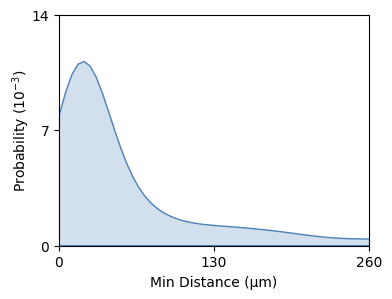

In [ ]:
# Plot the distribution of minimum distances
fig, ax = plt.subplots(figsize=(4, 3))
sns.kdeplot(x=min_dist_A_B, fill=True, ax=ax, color=[76/255, 129/255, 182/255, 1])
ax.set_xlabel('Min Distance (µm)')
ax.set_ylabel('Probability ($10^{-3}$)', labelpad=0)
ax.set_xlim([0, 260])
ax.set_ylim([0, 0.014])
ax.set_yticks([0, 0.007, 0.014])
ax.set_xticks([0, 130, 260])
ax.set_yticklabels([0, 7, 14])